In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
from astropy.modeling import models
from astropy import units as u
from astropy.modeling import models, fitting
from scipy.interpolate import UnivariateSpline
import pandas as pd

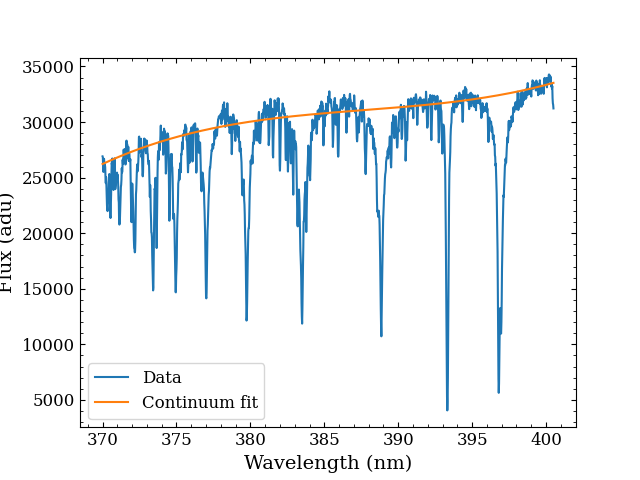

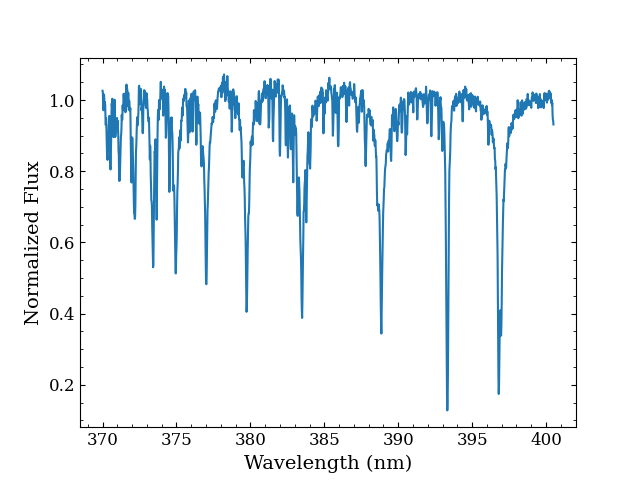

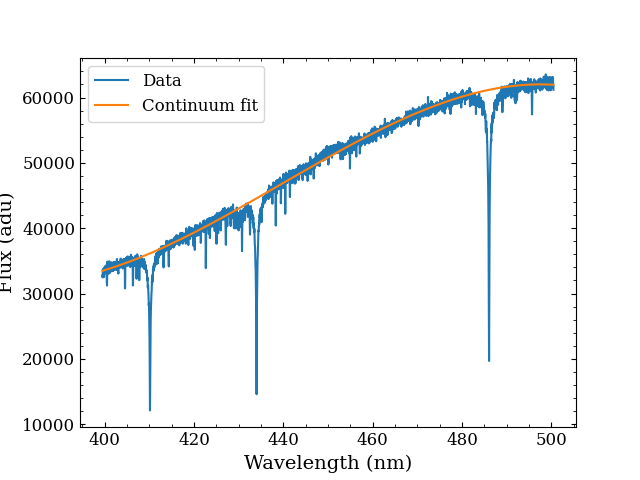

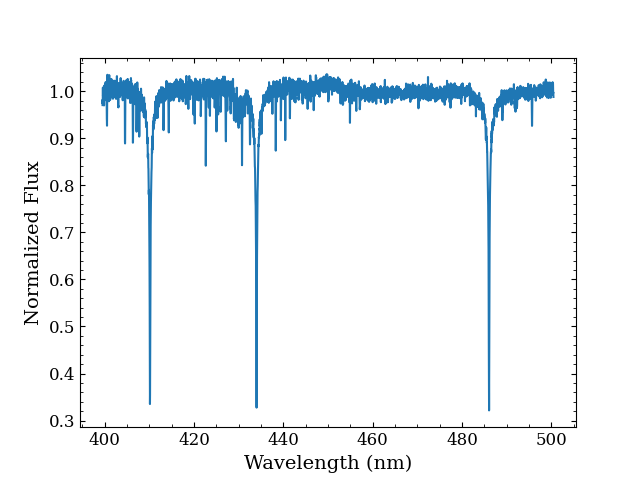

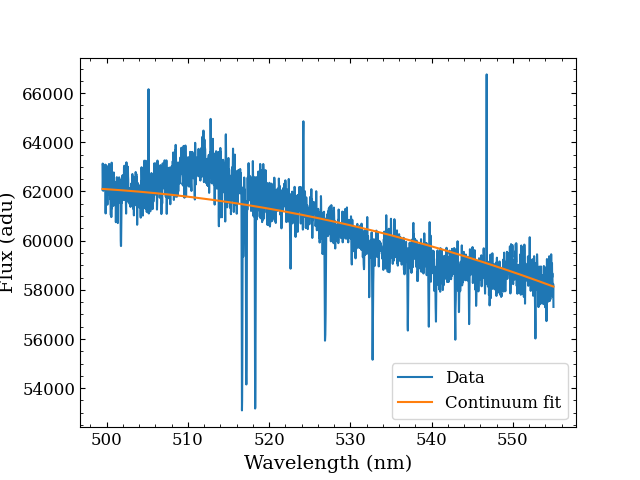

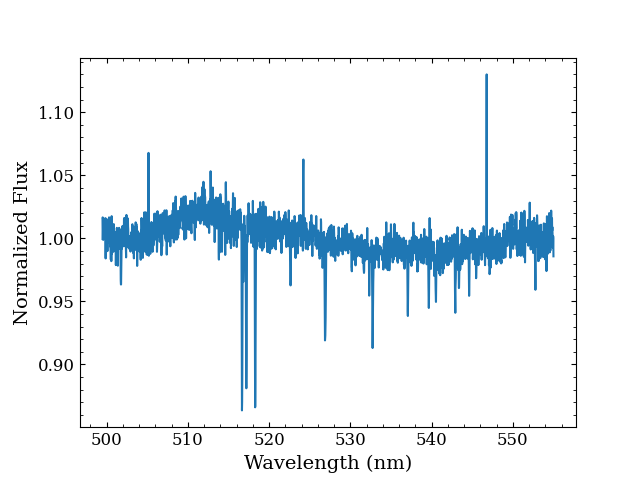

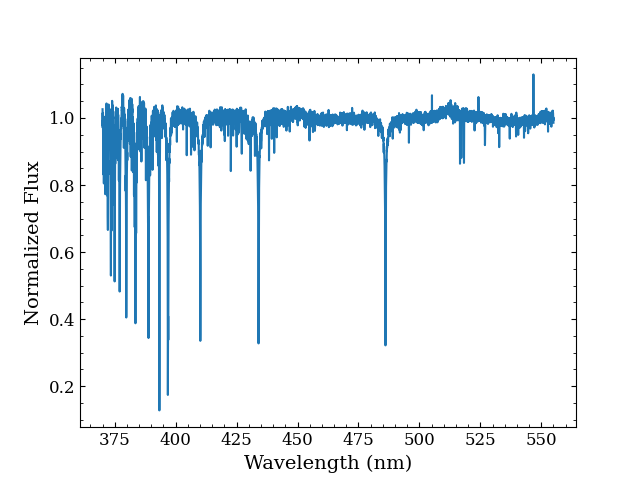

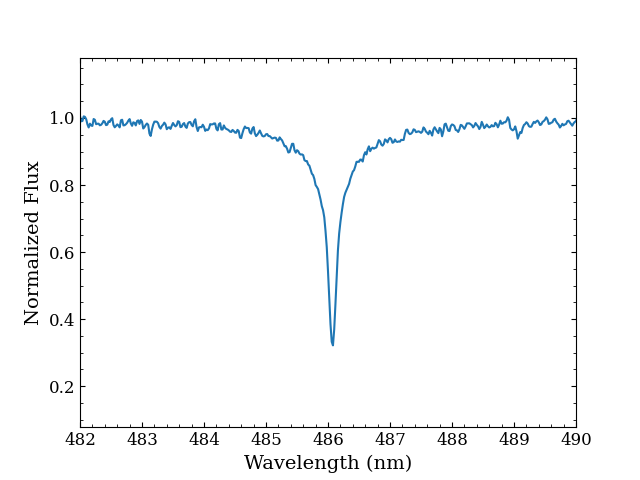

In [6]:
def norm_spec(data, arm):
    """Normalizes a given spectral dataset for a given arm.

    Parameters
    ----------
    data : astropy.io.fits.hdu.hdulist.HDUList
        An astropy .fits file opened using fits.open(...)
    arm : str
        Arm to be normalized. Avaliable options are: 'uvb', 'vis' and 'nir'.
    """
    
    def cont_fit(wave, flux, wavemin, wavemax, cont_regions, npol=3, plot=False):
        """Fits the continuum for a given spectral dataset.

        Parameters
        ----------
        wave : np.array
            Array of wavelengths.
        flux : np.array
            Array of fluces.
        wavemin : float
            Minimum wavelength to be used
        wavemax : float
            Maximum wavelength to be used
        cont_regions : list
            List of tuples containing wavelength regions
        npol : int, optional
            Number of polynomial points for continuum fitting, by default 3
        plot : bool, optional
            True to plot fitting results, False otherwise

        Returns
        -------
        wavecut : np.array
            Array of wavelengths over the given spectral window
        normflux : np.array
            Normalized flux for that window
        """
        
        # Slicing data to desired spectral window
        wave_reg = np.where((wave >= wavemin) & (wave <= wavemax))[0]
        wavecut = wave[wave_reg]
        fluxcut = flux[wave_reg]

        # Masking continuum regions
        cont_mask = np.logical_or.reduce([(wavecut >= start) & (wavecut <= end) for start, end in cont_regions])
                        
        # Fitting polynomial to continuum regions
        polynomial = models.Polynomial1D(degree=npol)
        fitter = fitting.LinearLSQFitter()
        cont_model = fitter(polynomial, wavecut[cont_mask], fluxcut[cont_mask])
        cont_fit = cont_model(wavecut)
        normflux = fluxcut/cont_fit

        # Plotting
        if plot:
            plt.figure()
            plt.plot(wavecut, fluxcut, label='Data')
            plt.plot(wavecut, cont_fit, label='Continuum fit')
            plt.xlabel('Wavelength (nm)')
            plt.ylabel('Flux (adu)')
            plt.legend()
            plt.savefig('/data/misfit/benlowe/results/contfit_' + plot, dpi=300, transparent=False, facecolor='white')
            
            plt.figure()
            plt.plot(wavecut, normflux)
            plt.xlabel('Wavelength (nm)')
            plt.ylabel('Normalized Flux')
            plt.savefig('/data/misfit/benlowe/results/norm_' + plot, dpi=300, transparent=False, facecolor='white')
            
        
        return wavecut, normflux
    
    def wind_overlap(wave, flux, wavemin_overlap, wavemax_overlap):
        """Gets the wavelengths and fluxes that are in the overlap region defined by wavemin_overlap and wavemax_overlap.

        Parameters
        ----------
        wave : np.array
            Wavelength array for the given spectral window.
        flux : np.array
            Normalized flux array for the given spectral window.
        wavemin_overlap : float
            Minimum wavelength at the start of the overlap.
        wavemax_overlap : float
            Maximum wavelength at the end of the overlap

        Returns
        -------
        flux_over : np.array
            Normalized fluxes in the overlap region
        """
        
        # Getting only the overlap region for this window
        index = np.where((wave >= wavemin_overlap) & (wave <= wavemax_overlap))[0]
        wave_over = wave[index]
        flux_over = flux[index]

        return flux_over

    
    if arm == 'uvb':
        
        # Extracting data from 370 to 555nm
        uvb_data = data[1].data
        uvb_slice = np.where((uvb_data['wave'] >= 370) & (uvb_data['wave'] <= 555))[0]
        
        uvb_wave = uvb_data['wave'][uvb_slice]
        uvb_flux = uvb_data['flux'][uvb_slice]


        # Splitting data into different windows, then fitting polynomials to each given a range of continuum points
        # Window 1: 
        # -> region 370 - 400.5nm 
        # -> 1st overlap 399.5 - 400.5nm
        wavemin_wind1 = 370
        wavemax_wind1 = 400.5
        cont_reg_wind1 = [(371.4, 371.6),
                         (381, 382),
                         (385, 386),
                         (394, 395),
                         (400, 405)]
        wave_wind1, fluxnorm_wind1 = cont_fit(wave=uvb_wave, flux=uvb_flux, wavemin=wavemin_wind1, wavemax=wavemax_wind1, 
                                              cont_regions=cont_reg_wind1, plot='wind1.png')
        
        # Window 2: 
        # -> region 399.5 - 500.5nm 
        # -> 1st overlap 399.5 - 400.5nm
        # -> 2nd overlap 499.5 - 500.5nm
        wavemin_wind2 = 399.5
        wavemax_wind2 = 500.5
        cont_reg_wind2 = [(400, 405),
                        (415, 425),
                        (450, 460),
                        (495, 500)]
        wave_wind2, fluxnorm_wind2 = cont_fit(wave=uvb_wave, flux=uvb_flux, wavemin=wavemin_wind2, wavemax=wavemax_wind2, 
                                              cont_regions=cont_reg_wind2, plot='wind2.png')
        
        # Window 3: 
        # -> region 499.5 - 555nm 
        # -> 1st overlap 499.5 - 500.5nm
        wavemin_wind3 = 499.5
        wavemax_wind3 = 555
        cont_reg_wind3 = [(500, 505),
                          (520, 530),
                          (550, 555)]
        wave_wind3, fluxnorm_wind3 = cont_fit(wave=uvb_wave, flux=uvb_flux, wavemin=wavemin_wind3, wavemax=wavemax_wind3, 
                                              cont_regions=cont_reg_wind3, plot='wind3.png')
        
        
        # Stitching together the windows
        # Overlap for window 1 with window 2
        flux_overlap12 = wind_overlap(wave=wave_wind1, flux=fluxnorm_wind1, wavemin_overlap=399.5, wavemax_overlap=400.5)

        # Overlap for window 2 with window 1
        flux_overlap21 = wind_overlap(wave=wave_wind2, flux=fluxnorm_wind2, wavemin_overlap=399.5, wavemax_overlap=400.5)

        # Overlap for window 2 with window 3
        flux_overlap23 = wind_overlap(wave=wave_wind2, flux=fluxnorm_wind2, wavemin_overlap=499.5, wavemax_overlap=500.5)

        # Overlap for window 3 with window 2
        flux_overlap32 = wind_overlap(wave=wave_wind3, flux=fluxnorm_wind3, wavemin_overlap=499.5, wavemax_overlap=500.5)

        # Taking the median of the overlaps
        stack_wind12 = np.stack((flux_overlap12, flux_overlap21), axis=0)
        med_wind12 = np.median(stack_wind12, axis=0)

        stack_wind23 = np.stack((flux_overlap23, flux_overlap32), axis=0)
        med_wind23 = np.median(stack_wind23, axis=0)
        
        
        # Stitching everything together
        uvb_flux_stitch1 = fluxnorm_wind1[np.where(wave_wind1 < 399.5)[0]]
        uvb_flux_stitch2 = med_wind12
        uvb_flux_stitch3 = fluxnorm_wind2[np.where((wave_wind2 > 400.5) & (wave_wind2 < 499.5))[0]]
        uvb_flux_stitch4 = med_wind23
        uvb_flux_stitch5 = fluxnorm_wind3[np.where(wave_wind3 > 500.5)[0]]

        uvb_flux_all = np.concatenate((uvb_flux_stitch1, uvb_flux_stitch2, uvb_flux_stitch3, uvb_flux_stitch4, uvb_flux_stitch5))

        
        # Plotting
        plt.figure()
        plt.plot(uvb_wave, uvb_flux_all)
        plt.xlabel('Wavelength (nm)')
        plt.ylabel('Normalized Flux')
        plt.savefig('/data/misfit/benlowe/results/specnorm.png', dpi=300, transparent=False, facecolor='white')
        
        plt.figure()
        plt.plot(uvb_wave, uvb_flux_all)
        plt.xlim(482, 490)
        plt.xlabel('Wavelength (nm)')
        plt.ylabel('Normalized Flux')
        plt.savefig('/data/misfit/benlowe/results/specnorm_hbeta.png', dpi=300, transparent=False, facecolor='white')
        
        return uvb_wave, uvb_flux_all


ra0103_s163 = fits.open('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_0103-7050_s163/ra_0103-7050_s163_data.fits')
ra0103_s163_wave, ra0103_s163_normflux = norm_spec(data=ra0103_s163, arm='uvb')

## VIS Spectra

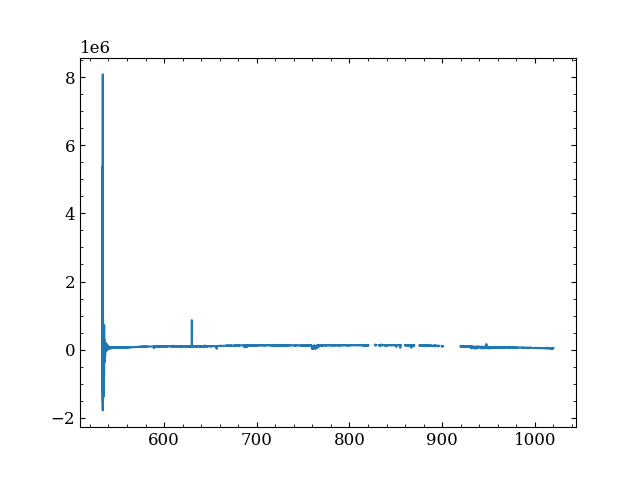

In [15]:
ra0103_s163 = fits.open('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_1604-2712_s24/ra_1604-2712_s24_data.fits')
vis_data = ra0103_s163[2].data

vis_wave = vis_data['wave']
vis_flux = vis_data['flux']
# uvb_cut = np.where((uvb_wave >= 370) & (uvb_wave <= 555))
# uvb_wave = uvb_wave[uvb_cut]
# uvb_flux = uvb_flux[uvb_cut]

plt.figure()
plt.plot(vis_wave, vis_flux)

### 560 - 600.5nm

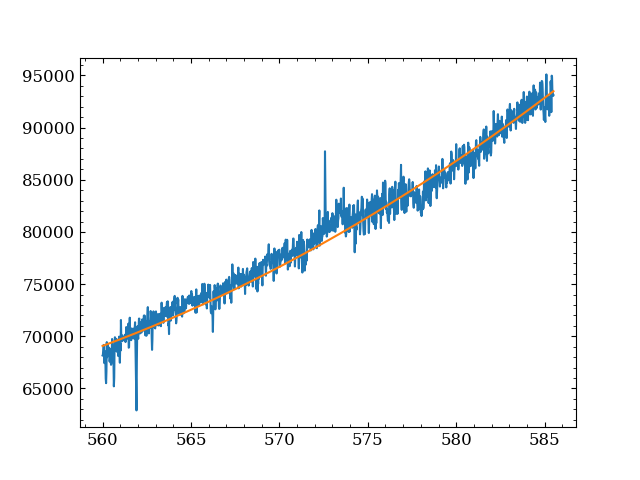

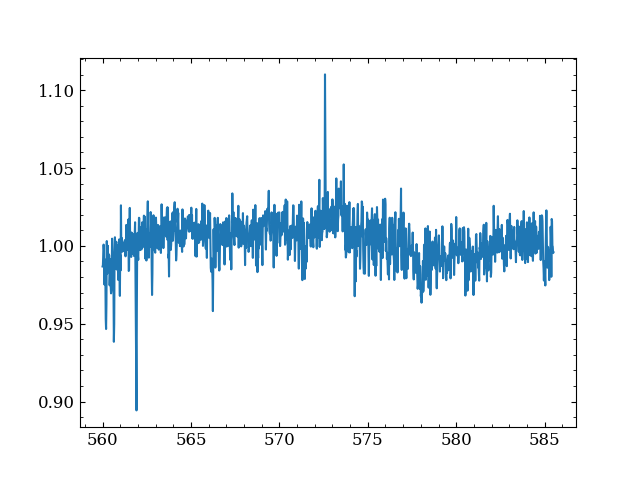

In [21]:
# Normalizing
wave_reg1 = np.where((vis_wave >= 560) & (vis_wave <= 585.5))[0]
vis_wavecut1 = vis_wave[wave_reg1]
vis_fluxcut1 = vis_flux[wave_reg1]

cont_regions1 = [(560, 565),
                 (575, 580),
                (582, 585)]
cont_mask1 = np.logical_or.reduce([(vis_wavecut1 >= start) & (vis_wavecut1 <= end) for start, end in cont_regions1])
                 

polynomial1 = models.Polynomial1D(degree=3)
fitter1 = fitting.LinearLSQFitter()
cont_model1 = fitter1(polynomial1, vis_wavecut1[cont_mask1], vis_fluxcut1[cont_mask1])
cont_fit1 = cont_model1(vis_wavecut1)
vis_normflux1 = vis_fluxcut1/cont_fit1


plt.figure()
plt.plot(vis_wavecut1, vis_fluxcut1)
plt.plot(vis_wavecut1, cont_fit1)

plt.figure()
plt.plot(vis_wavecut1, vis_normflux1)

### 560 - 600.5nm

## UVB Spectra


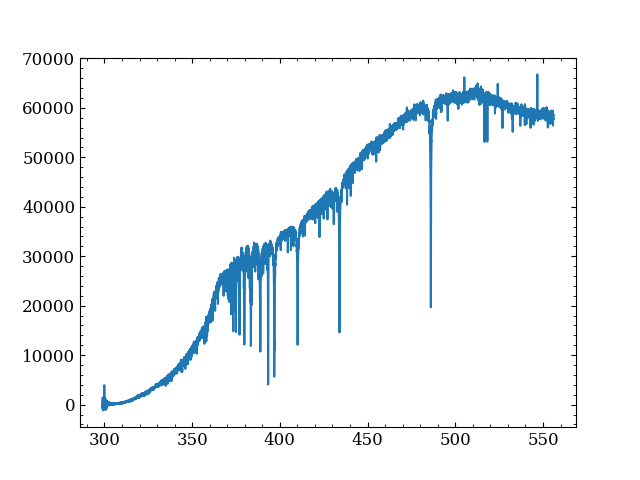

In [2]:
# Loading in data
# /data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_0103-7050_s163/ra_0103-7050_s163_data.fits
# /data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_1604-2712_s292/ra_1604-2712_s292_data.fits
ra0103_s163 = fits.open('/data/misfit/benlowe/xshooter/reduced_data/comb_spec/ra_0103-7050_s163/ra_0103-7050_s163_data.fits')
uvb_data = ra0103_s163[1].data

uvb_wave = uvb_data['wave']
uvb_flux = uvb_data['flux']
# uvb_cut = np.where((uvb_wave >= 570))
# uvb_wave = uvb_wave[uvb_cut]
# uvb_flux = uvb_flux[uvb_cut]

%matplotlib widget
plt.figure()
plt.plot(uvb_wave, uvb_flux)

In [6]:
wave_ = [i * 10 for i in uvb_wave]
flux_ = [i for i in uvb_flux]

wave_

[5700.0,
 5700.2,
 5700.4,
 5700.599999999999,
 5700.799999999999,
 5700.999999999999,
 5701.2,
 5701.4,
 5701.599999999999,
 5701.799999999999,
 5701.999999999999,
 5702.200000000001,
 5702.4,
 5702.6,
 5702.799999999999,
 5703.0,
 5703.199999999999,
 5703.4,
 5703.6,
 5703.8,
 5704.0,
 5704.2,
 5704.4,
 5704.599999999999,
 5704.8,
 5705.0,
 5705.2,
 5705.4,
 5705.599999999999,
 5705.799999999999,
 5705.999999999999,
 5706.2,
 5706.4,
 5706.599999999999,
 5706.799999999999,
 5706.999999999999,
 5707.200000000001,
 5707.4,
 5707.6,
 5707.799999999999,
 5708.0,
 5708.199999999999,
 5708.4,
 5708.6,
 5708.8,
 5709.0,
 5709.2,
 5709.4,
 5709.599999999999,
 5709.8,
 5710.0,
 5710.2,
 5710.4,
 5710.599999999999,
 5710.799999999999,
 5710.999999999999,
 5711.2,
 5711.4,
 5711.599999999999,
 5711.799999999999,
 5711.999999999999,
 5712.200000000001,
 5712.4,
 5712.6,
 5712.799999999999,
 5713.0,
 5713.199999999999,
 5713.4,
 5713.6,
 5713.8,
 5714.0,
 5714.2,
 5714.4,
 5714.599999999999,
 571

In [7]:
data_df = pd.DataFrame({'wave': np.array(wave_), 'flux': np.array(flux_)})
data_df.to_csv('/data/misfit/benlowe/xshooter_VIS_tomasz.csv')

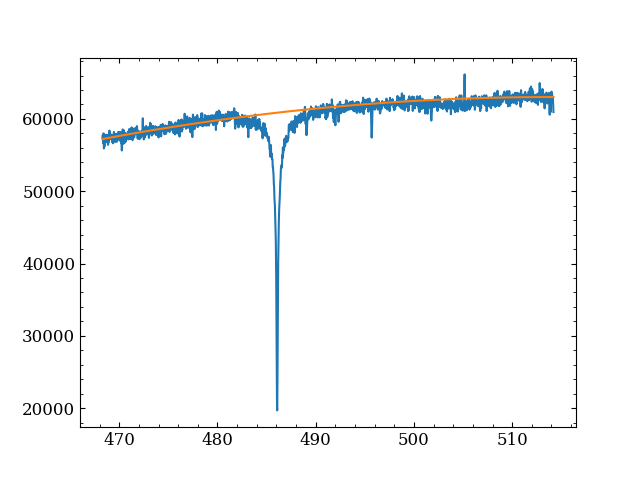

In [4]:
order24 = np.where((uvb_wave >= 468.3) & (uvb_wave <= 514.2)) 
wave24 = uvb_wave[order24]
flux24 = uvb_flux[order24]

cont_regions = [(469, 471.5),
                (478, 481),
                (493, 495),
                (510, 513)]
cont_mask = np.logical_or.reduce([(wave24 >= start) & (wave24 <= end) for start, end in cont_regions])
coeffs = np.polyfit(wave24[cont_mask], flux24[cont_mask], 2)
cont_fit1 = np.polyval(coeffs, wave24)


# poly = models.Polynomial1D(degree=2)
# fitter = fitting.LinearLSQFitter()
# cont_model = fitter(poly, wave24[cont_mask], flux24[cont_mask])
# cont_fit = cont_model(wave24)
# normflux = flux24/cont_fit

plt.figure()
plt.plot(wave24, flux24)
plt.plot(wave24, cont_fit1)

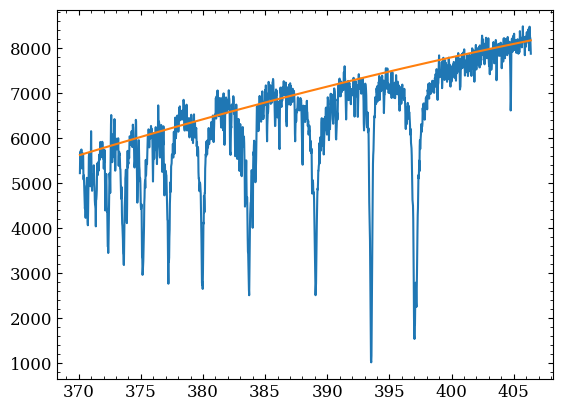

In [7]:
order2 = np.where((uvb_wave >= 370.1) & (uvb_wave <= 406.4)) 
wave2 = uvb_wave[order2]
flux2 = uvb_flux[order2]

cont_regions2 = [(371.7, 371.9),
                 ((381.2, 382)),
                 (385.5, 387),
    (405, 406.5)]
cont_mask = np.logical_or.reduce([(wave2 >= start) & (wave2 <= end) for start, end in cont_regions2])
coeffs = np.polyfit(wave2[cont_mask], flux2[cont_mask], 2)
cont_fit2 = np.polyval(coeffs, wave2)


plt.figure()
plt.plot(wave2, flux2)
plt.plot(wave2, cont_fit2)

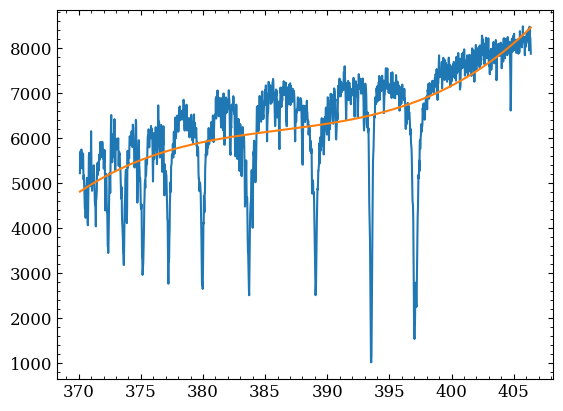

In [25]:
from specutils.fitting import fit_generic_continuum
from specutils import Spectrum1D

order2 = np.where((uvb_wave >= 370.1) & (uvb_wave <= 406.4)) 
wave2 = uvb_wave[order2]
flux2 = uvb_flux[order2]

spectrum = Spectrum1D(flux=flux2 * u.adu, spectral_axis=wave2 * u.nm)
continuum_model = fit_generic_continuum(spectrum)
fitted_continuum = continuum_model(wave2 * u.nm)
# normalized_flux = flux2 / fitted_continuum

plt.figure()
plt.plot(wave2, flux2)
plt.plot(wave2, fitted_continuum)

In [19]:
continuum_model(wave2)

AttributeError: 'numpy.ndarray' object has no attribute 'to'

In [15]:
help(continuum_model)

Help on QuantityModel in module specutils.utils.quantity_model object:

class QuantityModel(builtins.object)
 |  QuantityModel(unitless_model, input_units, return_units)
 |  
 |  The QuantityModel was created to wrap `~astropy.modeling.models` that do
 |  not have the ability to use `~astropy.units` in the parameters.
 |  
 |  Parameters
 |  ----------
 |  unitless_model : `~astropy.modeling.Model`
 |      A model that does not have units
 |  
 |  input_units : `~astropy.units`
 |      Units for the dispersion axis
 |  
 |  return_units : `~astropy.units`
 |      Units for the flux axis
 |  
 |  Notes
 |  -----
 |  When Astropy's modeling is updated so *all* models have the ability
 |  to have `~astropy.units.Quantity` on all parameters, then this will
 |  not be needed.
 |  
 |  Methods defined here:
 |  
 |  __call__(self, x, *args, **kwargs)
 |      Call self as a function.
 |  
 |  __delattr__(self, nm)
 |      Implement delattr(self, name).
 |  
 |  __dir__(self)
 |      Default d

### 370 - 400.5nm

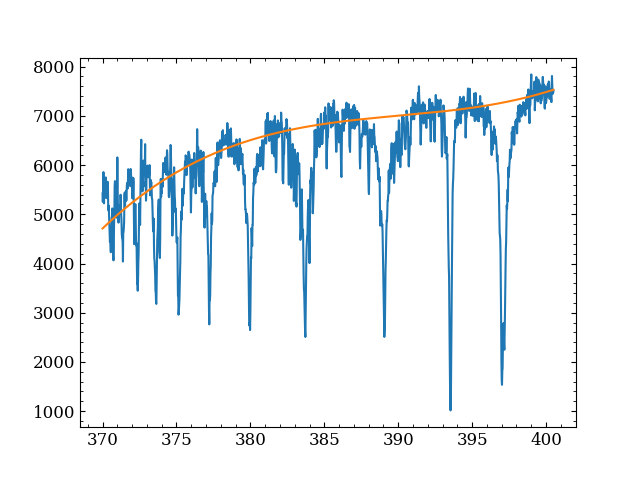

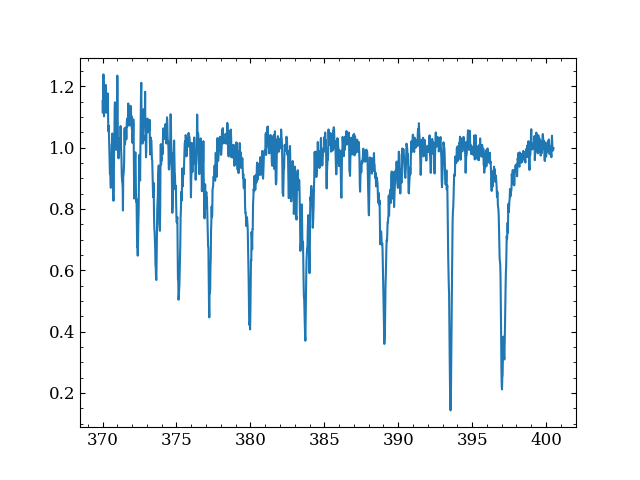

In [5]:
# Normalizing
wave_reg1 = np.where((uvb_wave >= 370) & (uvb_wave <= 400.5))[0]
uvb_wavecut1 = uvb_wave[wave_reg1]
uvb_fluxcut1 = uvb_flux[wave_reg1]

cont_regions1 = [(371.4, 371.6),
                 (381, 382),
                (385, 386),
                (394, 395),
                (400, 405)]
cont_mask1 = np.logical_or.reduce([(uvb_wavecut1 >= start) & (uvb_wavecut1 <= end) for start, end in cont_regions1])
                 

polynomial1 = models.Polynomial1D(degree=3)
fitter1 = fitting.LinearLSQFitter()
cont_model1 = fitter1(polynomial1, uvb_wavecut1[cont_mask1], uvb_fluxcut1[cont_mask1])
cont_fit1 = cont_model1(uvb_wavecut1)
uvb_normflux1 = uvb_fluxcut1/cont_fit1


plt.figure()
plt.plot(uvb_wavecut1, uvb_fluxcut1)
plt.plot(uvb_wavecut1, cont_fit1)

plt.figure()
plt.plot(uvb_wavecut1, uvb_normflux1)

### 399.5 - 500.5nm

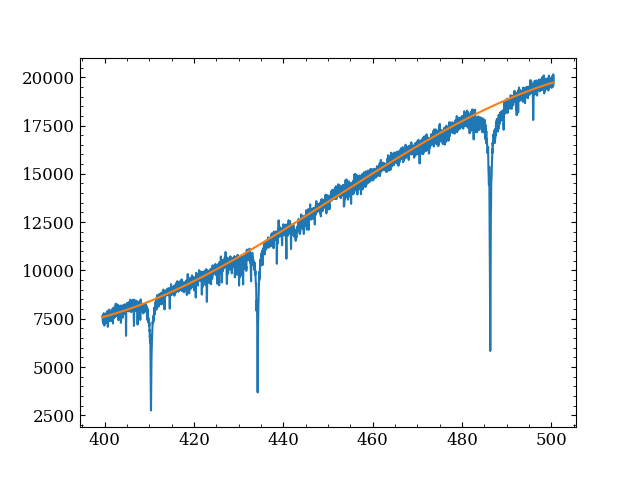

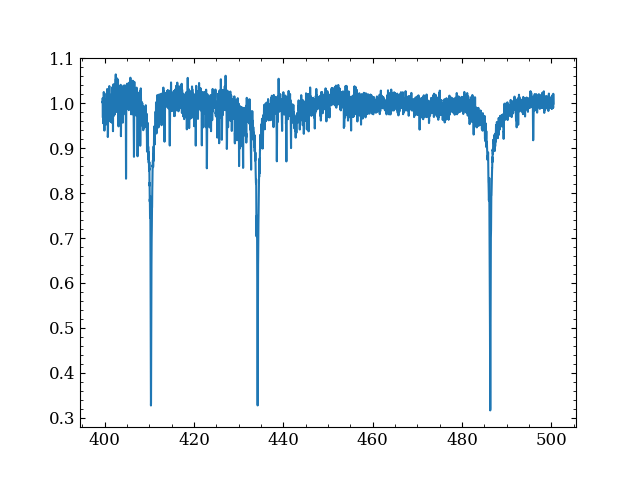

In [6]:
# Normalizing
wave_reg2 = np.where((uvb_wave >= 399.5) & (uvb_wave <= 500.5))[0]
uvb_wavecut2 = uvb_wave[wave_reg2]
uvb_fluxcut2 = uvb_flux[wave_reg2]

cont_regions2 = [(400, 405),
                (415, 425),
                (450, 460),
                (495, 500)]
cont_mask2 = np.logical_or.reduce([(uvb_wavecut2 >= start) & (uvb_wavecut2 <= end) for start, end in cont_regions2])
                 

polynomial2 = models.Polynomial1D(degree=3)
fitter2 = fitting.LinearLSQFitter()
cont_model2 = fitter2(polynomial2, uvb_wavecut2[cont_mask2], uvb_fluxcut2[cont_mask2])
cont_fit2 = cont_model2(uvb_wavecut2)
uvb_normflux2 = uvb_fluxcut2/cont_fit2


plt.figure()
plt.plot(uvb_wavecut2, uvb_fluxcut2)
plt.plot(uvb_wavecut2, cont_fit2)

plt.figure()
plt.plot(uvb_wavecut2, uvb_normflux2)

### 495.5 - 555nm

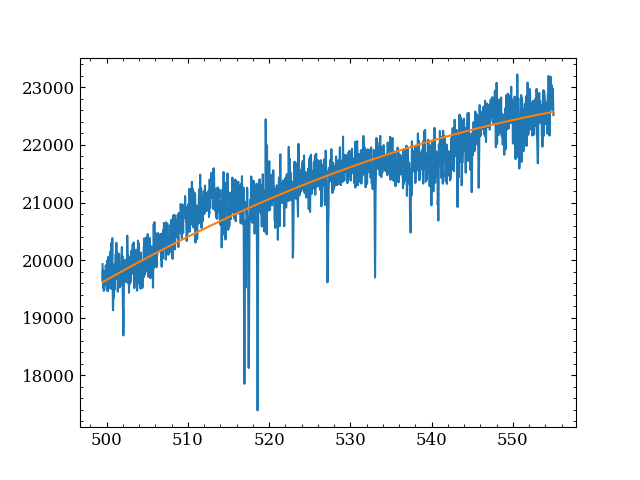

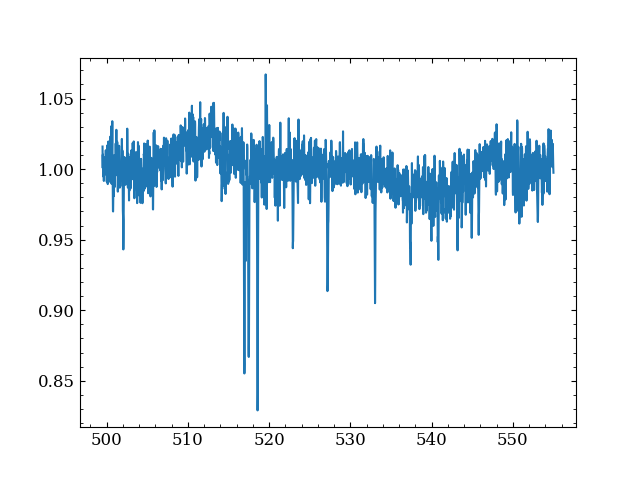

In [7]:
# Normalizing
wave_reg3 = np.where((uvb_wave >= 499.5) & (uvb_wave <= 555))[0]
uvb_wavecut3 = uvb_wave[wave_reg3]
uvb_fluxcut3 = uvb_flux[wave_reg3]

cont_regions3 = [(500, 505),
                 (520, 530),
                (550, 555)]
cont_mask3 = np.logical_or.reduce([(uvb_wavecut3 >= start) & (uvb_wavecut3 <= end) for start, end in cont_regions3])
                 

polynomial3 = models.Polynomial1D(degree=3)
fitter3 = fitting.LinearLSQFitter()
cont_model3 = fitter3(polynomial3, uvb_wavecut3[cont_mask3], uvb_fluxcut3[cont_mask3])
cont_fit3 = cont_model3(uvb_wavecut3)
uvb_normflux3 = uvb_fluxcut3/cont_fit3


plt.figure()
plt.plot(uvb_wavecut3, uvb_fluxcut3)
plt.plot(uvb_wavecut3, cont_fit3)

plt.figure()
plt.plot(uvb_wavecut3, uvb_normflux3)

### Stitching windows together

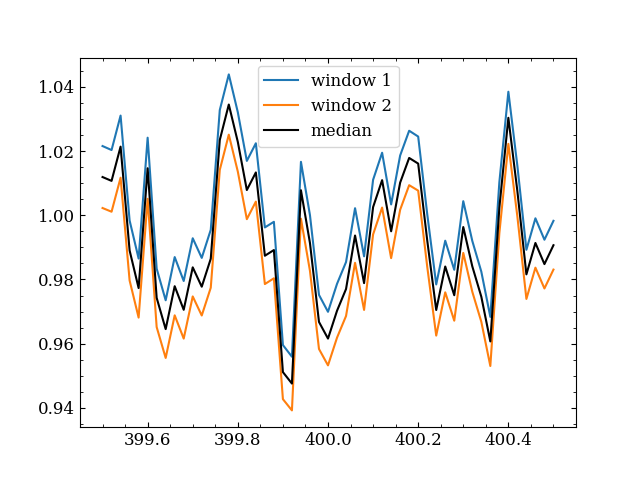

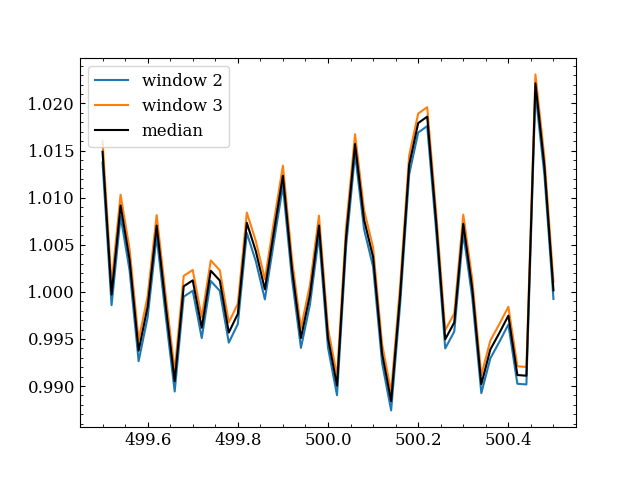

In [8]:
# ±5A index for each window
# Overlap for window 1 with window 2
index1 = np.where((uvb_wavecut1 >= 399.5) & (uvb_wavecut1 <= 400.5))[0]
wave_over1 = uvb_wavecut1[index1]
flux_over1 = uvb_normflux1[index1]

# Overlap for window 2 with window 1
index2 = np.where((uvb_wavecut2 >= 399.5) & (uvb_wavecut2 <= 400.5))[0]
wave_over2 = uvb_wavecut2[index2]
flux_over2 = uvb_normflux2[index2]

# Overlap for window 2 with window 3
index3 = np.where((uvb_wavecut2 >= 499.5) & (uvb_wavecut2 <= 500.5))[0]
wave_over3 = uvb_wavecut2[index3]
flux_over3 = uvb_normflux2[index3]

# Overlap for window 3 with window 2
index4 = np.where((uvb_wavecut3 >= 499.5) & (uvb_wavecut3 <= 500.5))[0]
wave_over4 = uvb_wavecut3[index4]
flux_over4 = uvb_normflux3[index4]


# Taking the median of the overlaps
stack_wind1wind2 = np.stack((flux_over1, flux_over2), axis=0)
med_wind1wind2 = np.median(stack_wind1wind2, axis=0)

stack_wind2wind3 = np.stack((flux_over3, flux_over4), axis=0)
med_wind2wind3 = np.median(stack_wind2wind3, axis=0)


# Plotting overlaps for window1-window2 and window2-window3
plt.figure()
plt.plot(wave_over1, flux_over1, label='window 1')
plt.plot(wave_over2, flux_over2, label='window 2')
plt.plot(wave_over1, med_wind1wind2, color='black', label='median')
plt.legend()

plt.figure()
plt.plot(wave_over3, flux_over3, label='window 2')
plt.plot(wave_over4, flux_over4, label='window 3')
plt.plot(wave_over3, med_wind2wind3, color='black', label='median')
plt.legend()

1475
51
4949
51
2725


/tmp/ipykernel_385556/2812206519.py:14: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure()


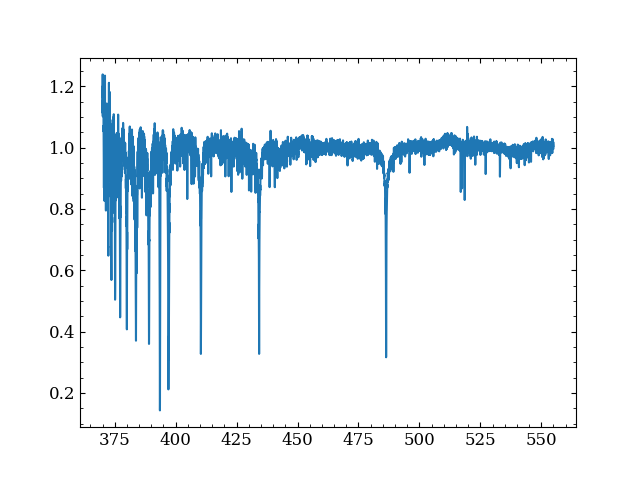

In [19]:
# Stitching everything together
uvb_flux_stitch1 = uvb_normflux1[np.where(uvb_wavecut1 < 399.5)[0]]
uvb_flux_stitch2 = med_wind1wind2
uvb_flux_stitch3 = uvb_normflux2[np.where((uvb_wavecut2 > 400.5) & (uvb_wavecut2 < 499.5))[0]]
uvb_flux_stitch4 = med_wind2wind3
uvb_flux_stitch5 = uvb_normflux3[np.where(uvb_wavecut3 > 500.5)[0]]

uvb_flux_all = np.concatenate((uvb_flux_stitch1, uvb_flux_stitch2, uvb_flux_stitch3, uvb_flux_stitch4, uvb_flux_stitch5))
print(len(uvb_flux_stitch1))
print(len(uvb_flux_stitch2))
print(len(uvb_flux_stitch3))
print(len(uvb_flux_stitch4))
print(len(uvb_flux_stitch5))
plt.figure()
plt.plot(uvb_wave, uvb_flux_all)

 [astropy.modeling.fitting]


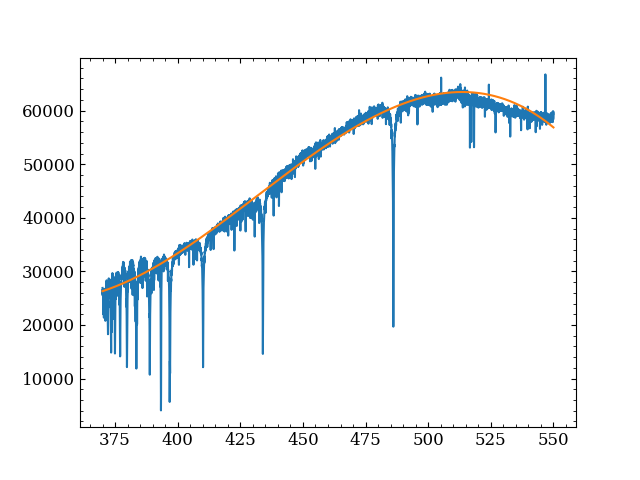

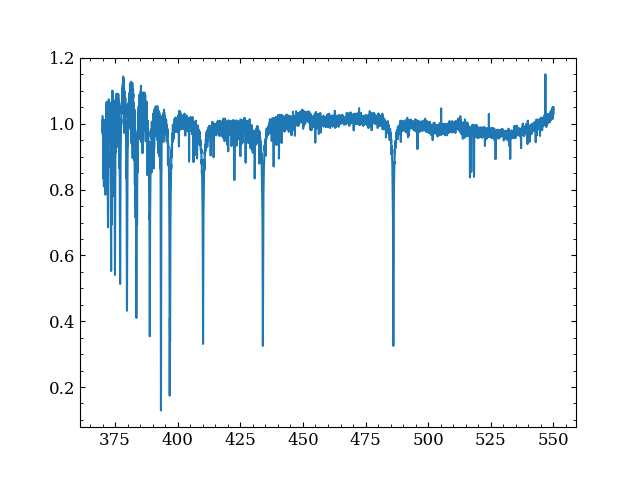

In [3]:
cont_regions = [(381, 382),
                (420, 430),
                (460, 480),
                (500, 510),
                (540, 550)]
cont_mask = np.logical_or.reduce([(uvb_wave >= start) & (uvb_wave <= end) for start, end in cont_regions])
                 

polynomial = models.Polynomial1D(degree=4)
fitter = fitting.LinearLSQFitter()
cont_model = fitter(polynomial, uvb_wave[cont_mask], uvb_flux[cont_mask])
cont_fit = cont_model(uvb_wave)
uvb_normflux = uvb_flux/cont_fit

# cont_points = np.array([440, 442, 450, 460, 508, 515])  # Wavelengths (Å)
# cont_indices = [np.abs(uvb_wave - point).argmin() for point in cont_points]

# spline_fit = UnivariateSpline(uvb_wave[cont_indices], uvb_flux[cont_indices], s=0)  # s=0 ensures no smoothing
# continuum_flux_fit = spline_fit(uvb_wave)


plt.figure()
plt.plot(uvb_wave, uvb_flux)
plt.plot(uvb_wave, cont_fit)

plt.figure()
plt.plot(uvb_wave, uvb_normflux)

In [18]:
cont_indices

[2000, 2100, 4000]